# 07. LPPLS — etykiety przyszłych spadków i walidacja chronologiczna

**Źródła:** `lppls_daily_validation.csv` (notatnik 04) i realne dzienne zamknięcia BTC-USD z 2015–2024. Notatnik nie estymuje LPPLS ponownie.

Celem `drop_D_hH` jest **co najmniej D% spadek w dowolnym z następnych H dni względem ceny na koniec dnia t**. Przyszły spadek jest etykietą, nigdy predyktorem. Końcowe H dni bez pełnego horyzontu mają `NA`. `label_end_hH` to data uzyskania pełnej etykiety. Wybór progu F1 jest wyłącznie na 3 wcześniejszych latach, z purgingiem etykiet.

**Ważne:** jeśli masz lokalny `btc_usd_2015_2024.csv`, musi zawierać rzeczywiste notowania, a nie plik przykładowy/syntetyczny.

**Zastrzeżenie:** progi 0 i 0,05 były już analizowane wcześniej; traktuj ten eksperyment jako analizę retrospektywną, nie w pełni niezależny test potwierdzający.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import confusion_matrix

ROOT = Path('.')
CI_FILE = ROOT / 'lppls_daily_validation.csv'
BTC_FILE = ROOT / 'btc_usd_2015_2024.csv'
OUT = ROOT / '07_wyniki_future_drop'
OUT.mkdir(parents=True, exist_ok=True)

HORIZONS = [30, 45, 60]
DROPS = [10, 15, 20]  # procenty
THRESHOLDS = [0.00, 0.02, 0.05, 0.10, 0.15, 0.20]
TEST_YEARS = [2021, 2022, 2023, 2024]
CALIBRATION_YEARS = 3


In [4]:
if BTC_FILE.exists():
    prices = pd.read_csv(BTC_FILE)
    print('Ceny z lokalnego pliku:', BTC_FILE)
else:
    import yfinance as yf
    raw = yf.download(
        'BTC-USD', start='2015-01-01', end='2025-01-01',
        interval='1d', auto_adjust=False, progress=False
    )
    if raw.empty:
        raise RuntimeError('Nie pobrano cen BTC; umieść lokalny plik BTC_FILE.')
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)
    prices = raw.reset_index()[['Date', 'Close']].rename(columns={'Close': 'price'})
    prices.to_csv(BTC_FILE, index=False)
    print('Pobrano i zapisano rzeczywiste ceny BTC:', BTC_FILE)

if 'Date' not in prices.columns and 'date' in prices.columns:
    prices = prices.rename(columns={'date': 'Date'})
if 'price' not in prices.columns and 'Close' in prices.columns:
    prices = prices.rename(columns={'Close': 'price'})
assert {'Date', 'price'}.issubset(prices.columns), 'Ceny muszą mieć Date i price (lub Close).'
prices = prices[['Date', 'price']].copy()
prices['Date'] = pd.to_datetime(prices['Date'], utc=True).dt.tz_convert(None).dt.normalize()
prices['price'] = pd.to_numeric(prices['price'], errors='raise')
prices = prices.loc[prices['Date'].between('2015-01-01', '2024-12-31')].copy()
prices = prices.sort_values('Date').reset_index(drop=True)
assert prices['Date'].min() == pd.Timestamp('2015-01-01')
assert prices['Date'].max() == pd.Timestamp('2024-12-31')
assert prices['Date'].is_unique, 'Powtórzone daty w cenach.'
assert prices['price'].notna().all() and (prices['price'] > 0).all()
# Wymagamy dziennego kalendarza BTC, inaczej H obserwacji != H dni.
assert prices['Date'].diff().dropna().eq(pd.Timedelta(days=1)).all(), (
    'Szereg cen BTC ma brakujące daty. Zweryfikuj dane; nie uzupełniaj cen przyszłością.'
)

if not CI_FILE.exists():
    alt = ROOT / '04_wyniki_walidacji_lppls' / 'lppls_daily_validation.csv'
    if alt.exists():
        CI_FILE = alt
    else:
        raise FileNotFoundError('Brak pliku lppls_daily_validation.csv')
ci = pd.read_csv(CI_FILE)
if 'date' not in ci.columns and 'win_end' in ci.columns:
    ci = ci.rename(columns={'win_end': 'date'})
assert {'date', 'confidence', 'n_all', 'n_accepted'}.issubset(ci.columns)
ci['date'] = pd.to_datetime(ci['date'], utc=True).dt.tz_convert(None).dt.normalize()
ci = ci.sort_values('date').reset_index(drop=True)
assert ci['date'].is_unique
assert ci['confidence'].between(0, 1).all()
assert (ci['n_accepted'] <= ci['n_all']).all()
assert (ci['n_all'] > 0).all()

print('Ceny:', len(prices), prices.Date.min().date(), prices.Date.max().date())
print('Dni CI:', len(ci), ci.date.min().date(), ci.date.max().date())


Ceny z lokalnego pliku: btc_usd_2015_2024.csv
Ceny: 3653 2015-01-01 2024-12-31
Dni CI: 3624 2015-01-30 2024-12-31


In [5]:
# Komórka 3 — etykiety: min. cena w następnych H dniach względem ceny w dniu t
# Liczymy na PEŁNEJ dziennej serii cen PRZED połączeniem z CI.
future = prices.rename(columns={'Date': 'date'}).copy()

for H in HORIZONS:
    # P(t+1), ..., P(t+H), NIE uwzględniamy ceny dnia t
    future_prices = pd.concat(
        [future['price'].shift(-k) for k in range(1, H + 1)], axis=1
    )
    min_price = future_prices.min(axis=1)
    label_end = future['date'].shift(-H)
    complete = label_end.notna()  # wymagamy pełnych H kolejnych dni

    future[f'future_drop_h{H}'] = (
        min_price.div(future['price']).sub(1)
    ).where(complete)
    future[f'label_end_h{H}'] = label_end  # data dostępności etykiety

    for D in DROPS:
        col = f'drop_{D}_h{H}'
        target = pd.Series(pd.NA, index=future.index, dtype='Int64')
        target.loc[complete] = (
            future.loc[complete, f'future_drop_h{H}'] <= -(D / 100)
        ).astype('int64')
        future[col] = target

# W zbiorze modelowym celowo nie przenosimy literature_bubble.
# Jest to inna, retrospektywna etykieta i nie może być predyktorem.
model_ci = ci[['date', 'confidence', 'n_all', 'n_accepted']].copy()
dataset = model_ci.merge(future, on='date', how='left', validate='one_to_one')
assert dataset['price'].notna().all(), 'Brak cen dla części dni z CI.'
assert dataset['date'].is_unique

# Kontrole na końcu szeregu: brak pełnego horyzontu oznacza NA, a NIE klasę 0.
for H in HORIZONS:
    expected = dataset['date'] + pd.Timedelta(days=H)
    valid = dataset[f'label_end_h{H}'].notna()
    assert (dataset.loc[valid, f'label_end_h{H}'] == expected.loc[valid]).all()
    for D in DROPS:
        col = f'drop_{D}_h{H}'
        assert dataset[col].isna().equals(~valid), f'Błędne NA w {col}'

dataset.to_csv(OUT / 'lppls_future_drop_dataset.csv', index=False)
print('Zapisano:', OUT / 'lppls_future_drop_dataset.csv')
print('Wiersze:', len(dataset))
display(dataset.head())


Zapisano: 07_wyniki_future_drop\lppls_future_drop_dataset.csv
Wiersze: 3624


,date,confidence,n_all,n_accepted,price,future_drop_h30,label_end_h30,drop_10_h30,drop_15_h30,drop_20_h30,future_drop_h45,label_end_h45,drop_10_h45,drop_15_h45,drop_20_h45,future_drop_h60,label_end_h60,drop_10_h60,drop_15_h60,drop_20_h60
0,2015-01-30,0.0,1,0,226.425003,-0.041135,2015-03-01,0,0,0,-0.041135,2015-03-16,0,0,0,-0.041135,2015-03-31,0,0,0
1,2015-01-31,0.0,1,0,217.464005,-0.001623,2015-03-02,0,0,0,-0.001623,2015-03-17,0,0,0,-0.001623,2015-04-01,0,0,0
2,2015-02-01,0.0,1,0,226.972000,-0.043446,2015-03-03,0,0,0,-0.043446,2015-03-18,0,0,0,-0.043446,2015-04-02,0,0,0
3,2015-02-02,0.0,1,0,238.229004,-0.088646,2015-03-04,0,0,0,-0.088646,2015-03-19,0,0,0,-0.088646,2015-04-03,0,0,0
4,2015-02-03,0.0,1,0,227.268005,-0.044692,2015-03-05,0,0,0,-0.044692,2015-03-20,0,0,0,-0.044692,2015-04-04,0,0,0


In [6]:
# Komórka 4 — kontrola kompletności i liczebności klas
summary_rows = []
for H in HORIZONS:
    for D in DROPS:
        y = dataset[f'drop_{D}_h{H}']
        summary_rows.append({
            'horizon': H,
            'drop_pct': D,
            'complete_days': int(y.notna().sum()),
            'positives': int((y == 1).sum()),
            'negatives': int((y == 0).sum()),
            'missing_horizon_days': int(y.isna().sum()),
            'positive_rate': float(y.dropna().mean())
        })
label_stats = pd.DataFrame(summary_rows)
display(label_stats.round(4))
label_stats.to_csv(OUT / '01_liczebnosci_etykiet.csv', index=False)


,horizon,drop_pct,complete_days,positives,negatives,missing_horizon_days,positive_rate
0,30,10,3594,1311,2283,30,0.3648
1,30,15,3594,890,2704,30,0.2476
2,30,20,3594,539,3055,30,0.1500
3,45,10,3579,1544,2035,45,0.4314
4,45,15,3579,1111,2468,45,0.3104
5,45,20,3579,737,2842,45,0.2059
6,60,10,3564,1698,1866,60,0.4764
7,60,15,3564,1270,2294,60,0.3563
8,60,20,3564,867,2697,60,0.2433


In [7]:
# Komórka 5 — funkcja oceny i chronologiczny walk-forward z usunięciem przeciekających etykiet
# Tylko CI, bez XGBoost. Porównujemy próg wybrany na kalibracji
# z progami stałymi oraz modelem zawsze przewidującym spadek.
def evaluate(y, p):
    y = np.asarray(y, dtype=int)
    p = np.asarray(p, dtype=int)
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    positives = tp + fn
    return dict(
        n=len(y), positives=int(positives), TP=int(tp), FP=int(fp),
        FN=int(fn), TN=int(tn), alarms=int(p.sum()),
        precision=tp / (tp + fp) if tp + fp else np.nan,
        recall=tp / positives if positives else np.nan,
        f1=(2 * tp / (2 * tp + fp + fn)) if positives else np.nan,
        specificity=tn / (tn + fp) if tn + fp else np.nan,
    )

fold_rows = []
prediction_rows = []
for H in HORIZONS:
    for D in DROPS:
        target = f'drop_{D}_h{H}'
        label_end = f'label_end_h{H}'
        valid_data = dataset.loc[dataset[target].notna()].copy()
        for year in TEST_YEARS:
            test_start = pd.Timestamp(year=year, month=1, day=1)
            calib_start = pd.Timestamp(year=year - CALIBRATION_YEARS, month=1, day=1)
            calib = valid_data.loc[
                (valid_data['date'] >= calib_start)
                & (valid_data['date'] < test_start)
                & (valid_data[label_end] < test_start)  # PURGING przyszłych etykiet
            ].copy()
            test = valid_data.loc[
                valid_data['date'].dt.year == year
            ].copy()
            if calib.empty or test.empty:
                continue
            assert calib[label_end].max() < test['date'].min()

            # Próg wybieramy WYŁĄCZNIE na danych kalibracyjnych.
            if int(calib[target].sum()) > 0:
                threshold_scores = []
                for theta in THRESHOLDS:
                    p = (calib['confidence'] > theta).astype(int)
                    stats = evaluate(calib[target], p)
                    threshold_scores.append((theta, stats['f1'], stats['alarms']))
                best = sorted(
                    threshold_scores, key=lambda x: (-x[1], x[2], x[0])
                )[0][0]
            else:
                best = np.nan  # nie dobieramy progu bez pozytywnych przykładów

            strategies = {'fixed_0': 0.0, 'fixed_005': 0.05}
            if pd.notna(best):
                strategies['walk_forward_F1'] = best

            for strategy, theta in strategies.items():
                pred = (test['confidence'] > theta).astype(int)
                stats = evaluate(test[target], pred)
                fold_rows.append(dict(
                    year=year, horizon=H, drop_pct=D,
                    strategy=strategy, threshold=theta,
                    calibration_n=len(calib),
                    test_start=test['date'].min(), test_end=test['date'].max(),
                    **stats
                ))
                part = test[['date', 'confidence', target]].rename(columns={target: 'y_true'}).copy()
                part['year'] = year
                part['horizon'] = H
                part['drop_pct'] = D
                part['strategy'] = strategy
                part['threshold'] = theta
                part['predicted_alarm'] = pred.values
                prediction_rows.append(part)

            # Baseline bez LPPLS: zawsze przewiduje spadek
            stats = evaluate(test[target], np.ones(len(test), dtype=int))
            fold_rows.append(dict(
                year=year, horizon=H, drop_pct=D,
                strategy='always_positive', threshold=np.nan,
                calibration_n=len(calib),
                test_start=test['date'].min(), test_end=test['date'].max(),
                **stats
            ))

folds = pd.DataFrame(fold_rows)
predictions = pd.concat(prediction_rows, ignore_index=True)
folds.to_csv(OUT / '02_wyniki_roczne_OOS.csv', index=False)
predictions.to_csv(OUT / '03_predykcje_dzienne_OOS.csv', index=False)
display(folds.head(15).round(3))


C:\Users\cynar\AppData\Local\Temp\ipykernel_22576\2170889965.py:90: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(folds.head(15).round(3))


,year,horizon,drop_pct,strategy,threshold,calibration_n,test_start,test_end,n,positives,TP,FP,FN,TN,alarms,precision,recall,f1,specificity
0,2021,30,10,fixed_0,0.00,1066,2021-01-01,2021-12-31,365,222,50,45,172,98,95,0.526,0.225,0.315,0.685
1,2021,30,10,fixed_005,0.05,1066,2021-01-01,2021-12-31,365,222,38,24,184,119,62,0.613,0.171,0.268,0.832
2,2021,30,10,walk_forward_F1,0.00,1066,2021-01-01,2021-12-31,365,222,50,45,172,98,95,0.526,0.225,0.315,0.685
3,2021,30,10,always_positive,NaN,1066,2021-01-01,2021-12-31,365,222,222,143,0,0,365,0.608,1.000,0.756,0.000
4,2022,30,10,fixed_0,0.00,1066,2022-01-01,2022-12-31,365,185,2,0,183,180,2,1.000,0.011,0.021,1.000
5,2022,30,10,fixed_005,0.05,1066,2022-01-01,2022-12-31,365,185,0,0,185,180,0,NaN,0.000,0.000,1.000
6,2022,30,10,walk_forward_F1,0.00,1066,2022-01-01,2022-12-31,365,185,2,0,183,180,2,1.000,0.011,0.021,1.000
7,2022,30,10,always_positive,NaN,1066,2022-01-01,2022-12-31,365,185,185,180,0,0,365,0.507,1.000,0.673,0.000
8,2023,30,10,fixed_0,0.00,1066,2023-01-01,2023-12-31,365,62,12,52,50,251,64,0.188,0.194,0.190,0.828
9,2023,30,10,fixed_005,0.05,1066,2023-01-01,2023-12-31,365,62,12,23,50,280,35,0.343,0.194,0.247,0.924


Łączne metryki dla lat 2021–2024:


,horizon,drop_pct,strategy,n,positives,TP,FP,FN,TN,alarms,precision,recall,f1,specificity
0,30,10,always_positive,1431,572,572,859,0,0,1431,0.400,1.000,0.571,0.000
1,30,10,fixed_0,1431,572,79,135,493,724,214,0.369,0.138,0.201,0.843
2,30,10,fixed_005,1431,572,59,63,513,796,122,0.484,0.103,0.170,0.927
3,30,10,walk_forward_F1,1431,572,79,135,493,724,214,0.369,0.138,0.201,0.843
4,30,15,always_positive,1431,342,342,1089,0,0,1431,0.239,1.000,0.386,0.000
5,30,15,fixed_0,1431,342,44,170,298,919,214,0.206,0.129,0.158,0.844
6,30,15,fixed_005,1431,342,33,89,309,1000,122,0.270,0.096,0.142,0.918
7,30,15,walk_forward_F1,1431,342,44,170,298,919,214,0.206,0.129,0.158,0.844
8,30,20,always_positive,1431,163,163,1268,0,0,1431,0.114,1.000,0.205,0.000
9,30,20,fixed_0,1431,163,22,192,141,1076,214,0.103,0.135,0.117,0.849


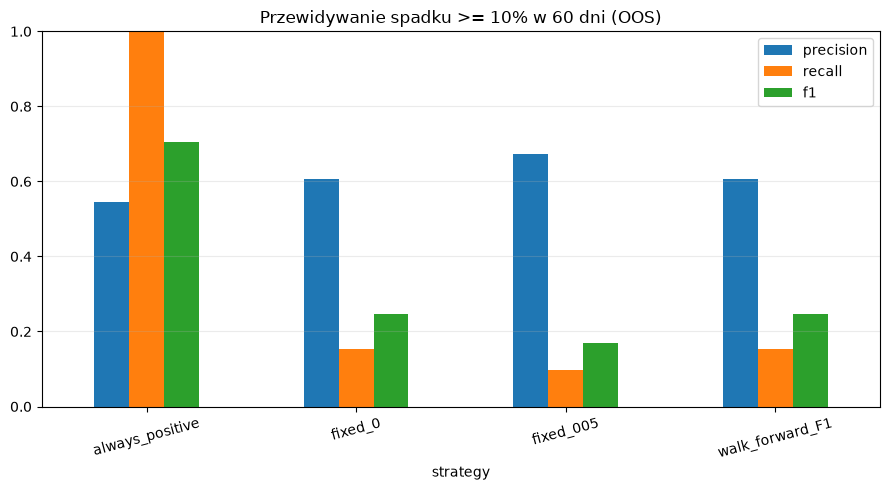

In [8]:
# Komórka 6 — zbiorczy wynik OOS (mikroagregacja TP/FP/FN/TN)
# F1 liczymy z sum macierzy pomyłek, nie średnią z F1 lat.
totals = (folds.groupby(['horizon', 'drop_pct', 'strategy'], as_index=False)
          [['n', 'positives', 'TP', 'FP', 'FN', 'TN', 'alarms']].sum())
totals['precision'] = totals['TP'] / (totals['TP'] + totals['FP']).replace(0, np.nan)
totals['recall'] = totals['TP'] / (totals['TP'] + totals['FN']).replace(0, np.nan)
totals['f1'] = 2 * totals['TP'] / (
    2 * totals['TP'] + totals['FP'] + totals['FN']
).replace(0, np.nan)
totals['specificity'] = totals['TN'] / (totals['TN'] + totals['FP']).replace(0, np.nan)
totals.to_csv(OUT / '04_wyniki_laczne_OOS.csv', index=False)
print('Łączne metryki dla lat 2021–2024:')
display(totals.round(3))

# Przykład wykresu: wszystkie strategie, spadek 10% w ciągu 60 dni
subset = totals.loc[(totals.horizon == 60) & (totals.drop_pct == 10)]
if not subset.empty:
    ax = subset.set_index('strategy')[['precision', 'recall', 'f1']].plot.bar(
        figsize=(9, 5), rot=15, title='Przewidywanie spadku >= 10% w 60 dni (OOS)'
    )
    ax.set_ylim(0, 1)
    ax.grid(axis='y', alpha=0.25)
    plt.tight_layout()
    plt.savefig(OUT / '05_porownanie_10proc_60dni.png', dpi=180)
    plt.show()
